# 02 — Offline Accuracy vs. Live SDN Controller Compute Budget (`EXP-0002`, `EXP-0005`, `EXP-0006`)

**Data Integrity Rule:** Every table and figure below is generated programmatically from immutable saved CSVs under `experiments/results/`. No numbers are hardcoded or manually edited.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent

sns.set_theme(style="whitegrid", context="notebook")
FIG_DIR = REPO_ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df_exp2 = pd.read_csv(REPO_ROOT / "experiments" / "results" / "EXP-0002" / "phase_summary.csv")
df_exp5 = pd.read_csv(REPO_ROOT / "experiments" / "results" / "EXP-0005" / "aggregated_summary.csv")
df_exp6 = pd.read_csv(REPO_ROOT / "experiments" / "results" / "EXP-0006" / "offline_benchmark_summary.csv")
exp6_detail = json.loads((REPO_ROOT / "experiments" / "results" / "EXP-0006" / "detailed_results.json").read_text(encoding="utf-8"))

print(f"Loaded EXP-0002 ({len(df_exp2)} load phases), EXP-0005 ({len(df_exp5)} budget levels, N=3), EXP-0006 ({len(df_exp6)} tier x model configs)")


Loaded EXP-0002 (7 load phases), EXP-0005 (6 budget levels, N=3), EXP-0006 (20 tier x model configs)


## 1. Live SDN Controller Saturation Curve (`EXP-0005`, Core-Pinned, $N=3$ Seeds, 95% CI)
At a modest `250 pps` spoofed table-miss flood (`~500 Packet-In/s` across `s1+s2`, zero flow-table refusals), synchronous CPU work per `Packet-In` hits a hard saturation cliff between **`1.0 ms`** and **`2.0 ms`**.


In [2]:
display_cols = [
    "inject_cpu_ms", "controller_packet_in_pps_mean", "controller_cpu_mean_pct_mean",
    "event_loop_lag_p95_ms_mean", "benign_new_flow_success_pct_mean", "benign_new_flow_p95_ms_mean"
]
df_exp5[display_cols]


,inject_cpu_ms,controller_packet_in_pps_mean,controller_cpu_mean_pct_mean,event_loop_lag_p95_ms_mean,benign_new_flow_success_pct_mean,benign_new_flow_p95_ms_mean
0,0.00,475.487,29.607,1.034,100.00,12.437
1,0.25,487.860,44.360,1.010,100.00,18.853
2,0.50,471.690,55.460,1.061,100.00,22.075
3,1.00,477.723,78.870,2.491,100.00,48.876
4,2.00,395.553,97.373,31.911,47.62,1293.723
5,4.00,215.907,97.580,24.939,16.67,437.908


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

x = df_exp5["inject_cpu_ms"]

# Panel A: Controller CPU & Event-loop lag p95
ax1 = axes[0]
ax1.errorbar(
    x, df_exp5["controller_cpu_mean_pct_mean"], yerr=df_exp5["controller_cpu_mean_pct_ci95"],
    marker="o", linewidth=2, capsize=4, color="#2563eb", label="Controller CPU Mean (%)"
)
ax1.axvspan(1.0, 2.0, color="#fef08a", alpha=0.35, label="Saturation Cliff (1.0–2.0 ms)")
ax1.set_xlabel("Injected Synchronous Compute per Packet-In (ms)")
ax1.set_ylabel("Controller CPU (% of 1 Pinned Core)", color="#2563eb")
ax1.set_ylim(0, 112)
ax1.set_title("(a) Core-Pinned os-ken CPU & Event-Loop Starvation (250 pps, N=3)")

ax1b = ax1.twinx()
ax1b.errorbar(
    x, df_exp5["event_loop_lag_p95_ms_mean"], yerr=df_exp5["event_loop_lag_p95_ms_ci95"],
    marker="s", linestyle="--", linewidth=2, capsize=4, color="#dc2626", label="Event-Loop Lag p95 (ms)"
)
ax1b.set_ylabel("Event-Loop Heartbeat Lag p95 (ms)", color="#dc2626")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax1b.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="lower right", fontsize=8.5, framealpha=0.95)

# Panel B: Processed Packet-In rate & Legitimate New-TCP Setup Success Rate
ax2 = axes[1]
ax2.errorbar(
    x, df_exp5["benign_new_flow_success_pct_mean"], yerr=df_exp5["benign_new_flow_success_pct_ci95"],
    marker="D", linewidth=2.2, capsize=4, color="#16a34a", label="Benign New-TCP Setup Success (%)"
)
ax2.axvspan(1.0, 2.0, color="#fef08a", alpha=0.35)
ax2.set_xlabel("Injected Synchronous Compute per Packet-In (ms)")
ax2.set_ylabel("Legitimate New-TCP Setup Success (%)", color="#16a34a")
ax2.set_ylim(0, 112)
ax2.set_title("(b) Legitimate New-Flow Collapse & Control-Plane Throughput Drop")

ax2b = ax2.twinx()
ax2b.errorbar(
    x, df_exp5["controller_packet_in_pps_mean"], yerr=df_exp5["controller_packet_in_pps_ci95"],
    marker="^", linestyle="--", linewidth=2, capsize=4, color="#7c3aed", label="Processed Packet-In/s"
)
ax2b.set_ylabel("Controller Processed Packet-In/s", color="#7c3aed")
ax2b.set_ylim(0, 560)

h3, l3 = ax2.get_legend_handles_labels()
h4, l4 = ax2b.get_legend_handles_labels()
ax2.legend(h3 + h4, l3 + l4, loc="lower left", fontsize=8.5)

plt.tight_layout()
out_fig = FIG_DIR / "fig02_exp0005_compute_budget_cliff.png"
plt.savefig(out_fig, dpi=220, bbox_inches="tight")
print(f"Saved figure -> {out_fig}")
plt.show()


Saved figure -> C:\Users\sijan\Desktop\intern\research\figures\fig02_exp0005_compute_budget_cliff.png


<Figure size 1350x480 with 4 Axes>

## 2. Offline Leakage-Free `InSDN` Quality vs. Reactive Single-Sample (`batch=1`) CPU Latency (`EXP-0006`)
Overlay every trained model's single-sample (`batch=1`) p95 CPU inference latency directly against **`EXP-0005`'s `1.0 ms` synchronous budget ceiling**, and quantify the speedup unlocked by micro-batching (`batch=64`).


In [4]:
df_exp6[[
    "tier", "n_features", "model", "test_macro_f1", "test_fpr",
    "batch1_p50_ms", "batch1_p95_ms", "batch64_per_flow_p50_ms",
    "batching_speedup_x", "exceeds_exp0005_1ms_p95"
]].sort_values(["tier", "batch1_p95_ms"])


,tier,n_features,model,test_macro_f1,test_fpr,batch1_p50_ms,batch1_p95_ms,batch64_per_flow_p50_ms,batching_speedup_x,exceeds_exp0005_1ms_p95
4,T1a_Unidirectional_OF,6,mlp,0.93672,0.13643,0.1951,0.2645,0.00333,58.53,False
0,T1a_Unidirectional_OF,6,logistic_regression,0.86324,0.29146,0.3302,0.5334,0.00551,59.88,False
2,T1a_Unidirectional_OF,6,xgboost,0.96575,0.06426,0.4616,0.7819,0.01026,44.97,False
1,T1a_Unidirectional_OF,6,lightgbm,0.96609,0.04367,0.5884,0.9076,0.01405,41.89,False
3,T1a_Unidirectional_OF,6,random_forest,0.96816,0.04388,5.5027,7.3133,0.08910,61.76,True
5,T1b_Bidirectional_OF,12,logistic_regression,0.88280,0.22814,0.1910,0.3787,0.00597,31.99,False
7,T1b_Bidirectional_OF,12,xgboost,0.97851,0.03546,0.3370,0.5189,0.00846,39.83,False
9,T1b_Bidirectional_OF,12,mlp,0.96342,0.07830,0.3293,0.7709,0.00656,50.17,False
6,T1b_Bidirectional_OF,12,lightgbm,0.97846,0.02849,0.5532,0.8274,0.01633,33.87,False
8,T1b_Bidirectional_OF,12,random_forest,0.97804,0.03109,5.9085,7.3303,0.11175,52.87,True


Saved figure -> C:\Users\sijan\Desktop\intern\research\figures\fig03_exp0006_pareto_f1_vs_latency.png


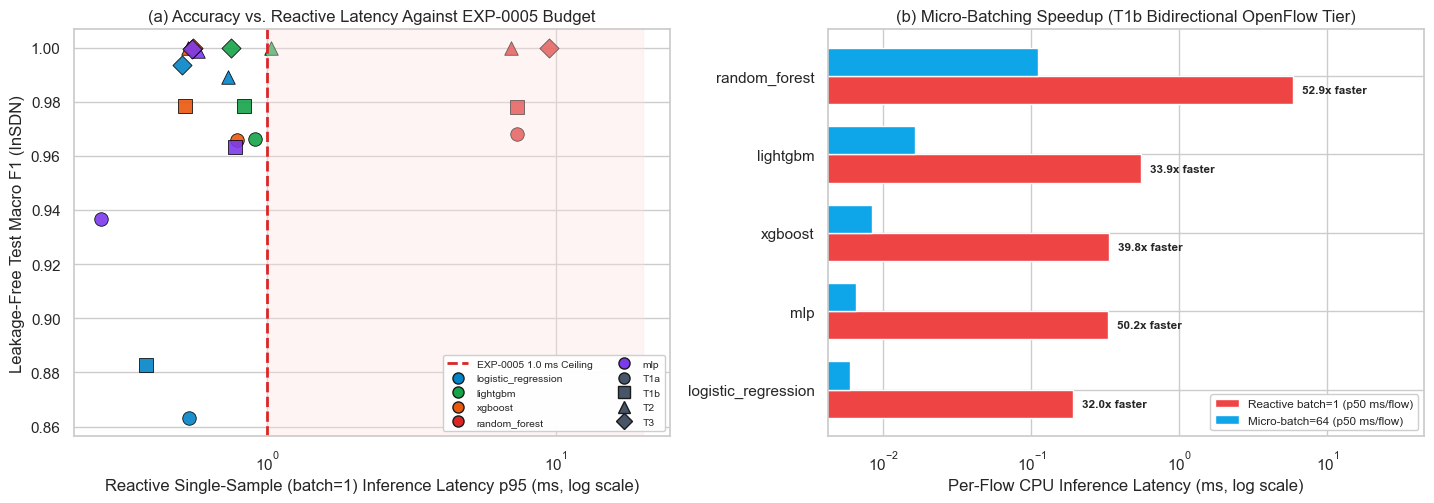

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2))

tier_markers = {
    "T1a_Unidirectional_OF": "o",
    "T1b_Bidirectional_OF": "s",
    "T2_Header_Flags": "^",
    "T3_Full_CICFlowMeter": "D",
}
model_colors = {
    "logistic_regression": "#0284c7",
    "lightgbm": "#16a34a",
    "xgboost": "#ea580c",
    "random_forest": "#dc2626",
    "mlp": "#7c3aed",
}

# Panel A: Macro F1 vs batch=1 p95 latency (log x-axis) with EXP-0005 1.0 ms wall
ax = axes[0]
for _, r in df_exp6.iterrows():
    ax.scatter(
        r["batch1_p95_ms"], r["test_macro_f1"],
        color=model_colors[r["model"]],
        marker=tier_markers[r["tier"]],
        s=95, edgecolor="black", linewidth=0.6, alpha=0.9
    )

ax.axvline(1.0, color="#dc2626", linestyle="--", linewidth=2, label="EXP-0005 Sync Budget (1.0 ms)")
ax.axvspan(1.0, max(df_exp6["batch1_p95_ms"].max() * 1.4, 20), color="#fee2e2", alpha=0.35, label="Controller Overload Zone")
ax.set_xscale("log")
ax.set_xlabel("Reactive Single-Sample (batch=1) Inference Latency p95 (ms, log scale)")
ax.set_ylabel("Leakage-Free Test Macro F1 (InSDN)")
ax.set_title("(a) Accuracy vs. Reactive Latency Against EXP-0005 Budget")

# Build clean dual legend (colors=model, shapes=tier)
from matplotlib.lines import Line2D
handles = [Line2D([0], [0], color="#dc2626", linestyle="--", lw=2, label="EXP-0005 1.0 ms Ceiling")]
for m, c in model_colors.items():
    handles.append(Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markeredgecolor="k", markersize=8, label=m))
for t, mk in tier_markers.items():
    handles.append(Line2D([0], [0], marker=mk, color="w", markerfacecolor="#475569", markeredgecolor="k", markersize=8, label=t.split("_")[0]))
ax.legend(handles=handles, loc="lower right", fontsize=7.5, ncol=2, framealpha=0.95)

# Panel B: Batch=1 vs Batch=64 per-flow latency for T1b_Bidirectional_OF
sub = df_exp6[df_exp6["tier"] == "T1b_Bidirectional_OF"].sort_values("batch1_p50_ms")
y_pos = np.arange(len(sub))
h = 0.36
axes[1].barh(y_pos - h/2, sub["batch1_p50_ms"], height=h, color="#ef4444", label="Reactive batch=1 (p50 ms/flow)")
axes[1].barh(y_pos + h/2, sub["batch64_per_flow_p50_ms"], height=h, color="#0ea5e9", label="Micro-batch=64 (p50 ms/flow)")
axes[1].set_xscale("log")
axes[1].set_xlim(right=45)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(sub["model"])
axes[1].set_xlabel("Per-Flow CPU Inference Latency (ms, log scale)")
axes[1].set_title("(b) Micro-Batching Speedup (T1b Bidirectional OpenFlow Tier)")
for idx, (_, r) in enumerate(sub.iterrows()):
    axes[1].text(
        r["batch1_p50_ms"] * 1.15, idx - h/2,
        f"{r['batching_speedup_x']:.1f}x faster", va="center", fontsize=8.5, fontweight="bold"
    )
axes[1].legend(loc="lower right", fontsize=8.5, framealpha=0.95)

plt.tight_layout()
out_fig = FIG_DIR / "fig03_exp0006_pareto_f1_vs_latency.png"
plt.savefig(out_fig, dpi=220, bbox_inches="tight")
print(f"Saved figure -> {out_fig}")
plt.show()


## 3. Destination-Port Shortcut Leakage Ablation
Quantifies how much adding `Dst Port` inflates simple linear/tree models on `InSDN` due to lab port bias (`53/443` vs `0/80`).


In [6]:
ab_df = pd.DataFrame(exp6_detail.get("dst_port_ablation", []))
base_t1a = df_exp6[(df_exp6["tier"] == "T1a_Unidirectional_OF") & (df_exp6["model"].isin(["logistic_regression", "lightgbm"]))][["tier", "model", "n_features", "test_macro_f1", "test_fpr"]]
pd.concat([base_t1a, ab_df], ignore_index=True)


,tier,model,n_features,test_macro_f1,test_fpr
0,T1a_Unidirectional_OF,logistic_regression,6,0.86324,0.29146
1,T1a_Unidirectional_OF,lightgbm,6,0.96609,0.04367
2,T1a_Unidirectional_OF+DstPort,logistic_regression,7,0.87409,0.28245
3,T1a_Unidirectional_OF+DstPort,lightgbm,7,0.99792,0.00120
